In [13]:
DEVICE="mps"
LLM_BASE_URL="http://127.0.0.1:8080/v1"

In [14]:
from sentence_transformers import CrossEncoder, SentenceTransformer

encoder = SentenceTransformer("intfloat/multilingual-e5-base", device=DEVICE)
reranker = CrossEncoder("BAAI/bge-reranker-v2-m3", device=DEVICE)

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 18498.47it/s]


In [15]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML
from openai import OpenAI

In [16]:
pd.set_option("display.max_colwidth", 300)
pd.set_option("display.max_rows", None)
def show(*, title: str, df: pd.DataFrame):
    display(HTML(f"""
        <h3 style="
            text-align: center;
            padding-bottom: 8px;
            border-bottom: 1px solid #888;
        ">{title}</h3>
    """))
    display(df)

In [17]:
chunks = pd.read_json("chunks.jsonl", lines=True)
chunk_vecs = np.load("chunk_embeddings.npy")
chunks["chunk_id"] = chunks["chunk_id"].astype(str)
q_df = pd.DataFrame(q for q in json.loads(Path("filmoskop_kb.json").read_text(encoding="utf-8"))["queries"])
q_vecs = encoder.encode(("query: " + q_df["query"]).tolist(), normalize_embeddings=True, batch_size=16)

assert len(q_df) == q_vecs.shape[0]
assert len(chunks) == chunk_vecs.shape[0]

print(f"Чанков: {len(chunks)}")
print(f"Вопросов: {len(q_df)}")

Чанков: 221
Вопросов: 66


In [18]:
import chromadb


COLLECTION_NAME = "knowledge_base"
client = chromadb.PersistentClient("chroma_db")
try:
    client.delete_collection(COLLECTION_NAME)
except Exception:
    pass


col = client.create_collection(name=COLLECTION_NAME, configuration={"hnsw": {"space": "cosine", "ef_search": 100}})
col.add(
    ids=chunks["chunk_id"].tolist(),
    embeddings=chunk_vecs.tolist(),
    documents=chunks["chunk_text"].tolist(),
    metadatas=chunks[["chunk_id", "doc_id", "title", "category", "chunk_idx", "token_count"]].to_dict("records")
)

В chroma всегда используется индекс, но на таком объеме данных он фактически равен полному перебору

In [19]:
# Проверка: HNSW на таком корпусе даёт то же, что точный перебор
chroma_top5 = col.query(query_embeddings=q_vecs.tolist(), n_results=5)["ids"]
exact_top5 = chunks["chunk_id"].to_numpy()[np.argsort(-(q_vecs @ chunk_vecs.T), axis=1)[:, :5]]
same = np.sum([set(a) == set(b) for a, b in zip(chroma_top5, exact_top5)])
show(title="Коллекция и проверка точности", df=pd.Series({"чанков в коллекции": col.count(), "запросов, где top-5 совпал с точным поиском": same}).to_frame("value"))

,value
чанков в коллекции,221
"запросов, где top-5 совпал с точным поиском",66


 Вообще для 221 чанка индекс избыточен, но в рамках задания проведём исследование когда он может понадобиться.
 Ответ на этот вопрос зависит не только от количества чанков в бд, но и от максимального допустимого latency(времени на поиск)
 Для примера возьмём максимально допустимую latency 20 мс.<br> Рассчитаем примерно при каком числе чанков мы не будем в него укладываться(расчет не учитывает накладные расходы на поиск в зависимости от хранилища, сетевое оно или в памяти)

In [20]:
def bench_latency(n: int) -> float:
    vecs = np.random.default_rng(42).standard_normal((n, 768), dtype=np.float32)
    q = vecs[0]
    t0 = time.perf_counter()
    for _ in range(10):
        scores = vecs @ q
        np.argpartition(-scores, 19)[:20] # 20 лучших
    return (time.perf_counter() - t0) / 10 * 1000

sizes = [1_000, 10_000, 20_000, 100_000, 200_000, 250_000]
scale = pd.DataFrame({"chunks": sizes, "latency_ms": [bench_latency(n) for n in sizes]})
scale["memory_gb"] = scale["chunks"] * 768 * 4 / 1e9

# Точный поиск считает все векторы по очереди, поэтому время растёт линейно: берём время на один вектор
LIMIT_MS = 20                                                 # допустимая задержка поиска
ms_per_chunk = scale["latency_ms"].iloc[-1] / scale["chunks"].iloc[-1]
n_limit = int(LIMIT_MS / ms_per_chunk)
show(title="Точный поиск: задержка от размера корпуса", df=scale.round(3))
show(title="Граница", df=pd.Series({"чанков при задержке 0,02 с": n_limit, "память под вектора, ГБ": n_limit * 768 * 4 / 1e9}).to_frame("value").round(2))



,chunks,latency_ms,memory_gb
0,1000,0.104,0.003
1,10000,0.754,0.031
2,20000,1.983,0.061
3,100000,10.287,0.307
4,200000,19.647,0.614
5,250000,31.971,0.768


,value
"чанков при задержке 0,02 с",156390.00
"память под вектора, ГБ",0.48


### Вывод по необходимости индекса
Тестовые замеры, подтверждают что скорость поиска растёт линейно в зависимости от размера корпуса векторов. <br> 
Применять и настраивать индекс(сравнивать метрики с эталоном) при допустимом latency 20 мс, потребуется при **~170_000** векторов<br>
Стоит отметить что с ростом числа векторов растёт и потребляемая память для хранения, и это тоже нужно учитывать, применять при необходимости механизмы оптимизации размера(pq, sq)

## Поиск

### Retriver

In [21]:
def retrieve(query: str, k: int = 5, threshold: float = 0.0, category: str | None = None) -> pd.DataFrame:
    """Запрос -> эмбеддинг -> поиск в Chroma -> порог -> top-k чанков с метаданными."""
    q = encoder.encode("query: " + query, normalize_embeddings=True)
    res = col.query(
        query_embeddings=[q.tolist()],
        n_results=k,
        where={"category": category} if category else None,
        include=["documents", "metadatas", "distances"],
    )
    out = pd.DataFrame(res["metadatas"][0])
    out["score"] = 1 - np.array(res["distances"][0])
    out["text"] = res["documents"][0]
    return out[out["score"] >= threshold].reset_index(drop=True)             # отсекаем слабые чанки

#### Фильтрация по метаданным на одном примере

In [22]:
q1 = "сколько устройств могут смотреть одновременно"
show(title="Без фильтра", df=retrieve(q1)[["doc_id", "title", "category", "score"]].round(3))
show(title="Только категория «Подписка и оплата»", df=retrieve(q1, category="Подписка и оплата")[["doc_id", "title", "category", "score"]].round(3))

,doc_id,title,category,score
0,44,Сколько устройств у одного зрителя,Устройства и качество,0.867
1,99,Совместный просмотр,Функции и контент,0.853
2,24,Какой тариф подойдёт именно вам,Подписка и оплата,0.845
3,85,Ошибка P-102: превышен лимит просмотров,Ошибки воспроизведения,0.839
4,166,Привязанные устройства и их лимит,Устройства и качество,0.836


,doc_id,title,category,score
0,24,Какой тариф подойдёт именно вам,Подписка и оплата,0.845
1,113,Тарифы «Фильмоскопа»,Подписка и оплата,0.818
2,170,Черновик: как выбрать подходящий тариф,Подписка и оплата,0.810
3,168,Первые дни в «Фильмоскопе»,Подписка и оплата,0.804
4,25,Тарифы «Фильмоскопа» (архив),Подписка и оплата,0.798


In [23]:
# dense retriver on all queries
all_hits = []
all_elapsed = []

# прогрев бд
for q in q_df["query"][:5]:
    retrieve(q)
for q in q_df["query"]:
    t0 = time.perf_counter()
    all_hits.append(retrieve(q, k=20, threshold=-1.0))
    all_elapsed.append((time.perf_counter() - t0) * 1000)


#### Выбор порога релевантности

In [24]:
# вычисляем лучшие скоры для answerable и gap
top1 = pd.Series([h["score"].max() for h in all_hits], index=q_df.index)
answerable_idx, gap_idx = q_df.index[q_df["kind"] != "gap"], q_df.index[q_df["kind"] == "gap"]
top1_ans, top1_gap = top1.iloc[answerable_idx], top1.iloc[gap_idx]
res = pd.DataFrame({"top1 answerable": top1_ans.describe(), "top1 gap": top1_gap.describe()})
show(title="Статистика по топ 1 скору по всем запросам", df=res)

,top1 answerable,top1 gap
count,56.000000,10.000000
mean,0.858792,0.833071
std,0.020939,0.022346
min,0.805938,0.786572
25%,0.845019,0.824827
50%,0.857813,0.831282
75%,0.868778,0.839793
max,0.902197,0.872099


Из распределения видно что скоры gap и answerable пересекаются, p50 gap вопросов выше min answerable, нельзя подобрать порог так чтобы он отсекал все gap и пропускал все answerable<br>
Попробуем подобрать порог с минимальной потерей

In [25]:
candidates = np.sort(pd.concat([top1_ans, top1_gap]).unique())  # все уникальные скоры как кандидаты

rows = []
for t in candidates:
    fr = int((top1_ans < t).sum())   # ложный отказ: ответ есть, а мы отказали
    fa = int((top1_gap >= t).sum())  # ложный приём: ответа нет, а мы ответили (галлюцинация)
    rows.append({"порог": round(t, 3),
                 "ложные_отказы": fr,
                 "ложные_приёмы": fa,
                 "потери_1к1": fr + fa,
                 "потери_1к3": fr + 3 * fa})  # если галлюцинация в 3 раза хуже})

sweep = pd.DataFrame(rows).sort_values("потери_1к3")
show(title="Подбор порога", df=sweep.head(10))

,порог,ложные_отказы,ложные_приёмы,потери_1к1,потери_1к3
10,0.835,4,4,8,16
18,0.841,10,2,12,16
11,0.835,5,4,9,17
19,0.842,11,2,13,17
16,0.839,9,3,12,18
12,0.836,6,4,10,18
8,0.830,3,5,8,18
20,0.843,12,2,14,18
5,0.828,1,6,7,19
9,0.833,4,5,9,19


На данном наборе данных невозможно корректно определить порог. Слишком мало документов и вопросов, нет тестовой выборки. При таких условиях разница между показателяим будет на уровне шума. Но я просто покажу как я бы подошёл к выбору порога.<br>

При подборе порога используется компромисс между двумя типами ошибок:

 - Ложный отказ (False Reject): релевантный контекст присутствует в базе, но его оценка ниже порога, поэтому система отказывается отвечать, хотя необходимая информация доступна.

 - Ложный приём (False Accept): релевантного контекста нет, но оценка найденного чанка достигает порога. В результате нерелевантный контекст передаётся LLM, что повышает риск генерации неподтверждённого ответа.

При низком пороге увеличивается вероятность пропуска нерелевантных чанков в контекст модели. При высоком пороге возрастает количество ложных отказов, поскольку система может отбрасывать и релевантные чанки.

Для нашей системы цена ложного приёма выше цены ложного отказа: генерация ответа на основании нерелевантного контекста потенциально опаснее, чем отказ при наличии информации в базе. Поэтому при оценке порогов используется взвешенная функция потерь:
$$
L = False Reject + 3 × False Accept
$$

Таким образом, ложный приём получает штраф, втрое превышающий штраф за ложный отказ.(значение 3 выбрано для примера, в реальных системах это определяется на стороне бизнеса)

По результатам перебора порогов значение 0.835 обеспечивает приемлемый компромисс между двумя типами ошибок. При этом сохраняется относительно небольшое количество ложных отказов, а число ложных приёмов ограничивается с учётом их повышенной стоимости.

В качестве **начального рабочего значения выбираем порог 0.835**. Его окончательная пригодность должна быть подтверждена на независимой выборке и при оценке качества ответов LLM. Дополнительно необходимо учитывать, что порог retrieval не гарантирует отсутствие галлюцинаций: надёжность системы также зависит от корректного заземления промпта и способности модели отказываться от ответа при недостаточности подтверждающего контекста.


In [26]:
THRESHOLD=0.835

### Функция сбора метрик

,value
recall@5,0.64
precision@5,0.18
mrr,0.52
elapsed_ms,21.52


,recall@5,precision@5,mrr,elapsed_ms
kind,,,,
exact,0.90,0.19,0.59,45.30
multi,0.59,0.27,0.57,11.23
semantic,0.52,0.12,0.44,13.83


,recall
1,0.259
3,0.554
5,0.643
10,0.857
20,0.964


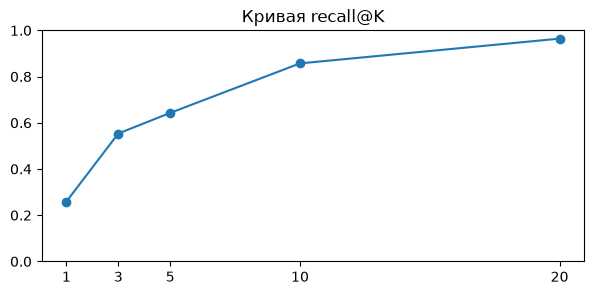

In [27]:
KS = [1, 3, 5, 10, 20]


def evaluate(
    hits_by_query: dict[int, pd.DataFrame], elapsed: list[float]
) -> pd.DataFrame:
    """Расчёт retrieval-метрик для answerable-запросов."""
    rows = []
    for i in answerable_idx:
        rel = set(q_df.loc[i, "relevant_docs"])
        hits = hits_by_query[i]
        row = {
            "qi": i,
            "query": q_df.loc[i, "query"],
            "kind": q_df.loc[i, "kind"],
            "elapsed_ms": elapsed[i]
        }
        # Recall@K.
        for k in KS:
            docs_k = hits["doc_id"].head(k).unique()
            row[f"recall@{k}"] = (
                len(set(docs_k) & rel) / len(rel)
            )
        # Precision@5.
        docs_5 = hits["doc_id"].head(5).unique()
        row["precision@5"] = (
            len(set(docs_5) & rel) / len(docs_5)
            if len(docs_5)
            else 0.0
        )

        # MRR.
        ranked_docs = hits["doc_id"].drop_duplicates().tolist()

        first = next(
            (
                rank
                for rank, doc_id in enumerate(ranked_docs, start=1)
                if doc_id in rel
            ),
            None,
        )

        row["mrr"] = 1 / first if first else 0.0

        rows.append(row)

    return pd.DataFrame(rows)


baseline_hits = {
    i: all_hits[i]
    for i in answerable_idx
}
baseline_metrics = evaluate(baseline_hits, all_elapsed)

def show_retriver_metrics(df: pd.DataFrame, name: str):
    cols = ["recall@5", "precision@5", "mrr", "elapsed_ms"]
    show(title=f"{name} retriver метрики", df=df[cols].mean().round(2).to_frame("value"))
    show(title=f"{name} retriver метрики по типам запросов", df=df.groupby("kind")[cols].mean().round(2))

show_retriver_metrics(baseline_metrics, "baseline")

# Кривая recall@K (без порога)
curve = baseline_metrics[[f"recall@{k}" for k in KS]].mean()
curve.index = KS
show(title="recall@K", df=curve.round(3).to_frame("recall"))
curve.plot(marker="o", xticks=KS, ylim=(0, 1), figsize=(7, 3), title="Кривая recall@K")


metrics_before = baseline_metrics.copy()                   # снимок "до" для сравнения после улучшений
baseline_metrics.to_csv("baseline_per_query.csv", index=False)

## Итоговый вывод по этапу 3

- **Выбор хранилища.** Для проекта выбрана ChromaDB. Она предоставляет удобный Python API, персистентное хранение и встроенную фильтрацию по метаданным. FAISS потребовал бы дополнительной реализации работы с метаданными и хранением, а возможности Qdrant для текущего объёма данных избыточны.

- **Настройка индекса.** Создана коллекция из 221 чанка с использованием HNSW и косинусного расстояния (`space="cosine"`, `ef_search=100`). Состав top-5 результатов совпал с точным поиском на всех 66 проверенных запросах. Отдельный эксперимент показал, что точный поиск укладывается в ограничение 20 мс примерно до 170 тысяч векторов. Для текущего корпуса точного поиска достаточно; пересмотреть решение стоит при приближении к сотням тысяч векторов или превышении допустимой задержки.

- **Retrieval-пайплайн.** Реализована полная последовательность: преобразование запроса в эмбеддинг, поиск ближайших чанков, преобразование расстояния в similarity, фильтрация по порогу и получение top-K результатов вместе с текстом и метаданными.

- **Порог отсечения.** Исследованы распределения максимального сходства для 56 answerable- и 10 gap-запросов. Распределения пересекаются, поэтому разделить эти типы запросов одним порогом без ошибок невозможно. В качестве предварительного значения выбран `threshold = 0.835`, поскольку ложный приём нерелевантного контекста считается более дорогой ошибкой.

- **Фильтрация по метаданным.** Проверена фильтрация по категории «Подписка и оплата». В результатах остаются только чанки указанной категории. Фильтрация выполняется непосредственно средствами ChromaDB.

- **Baseline retrieval.** Оценка проведена на 56 answerable-запросах, без включения gap-запросов. Без порога отсечения получены: `Precision@5 = 0.182`, `Recall@5 = 0.643`, `MRR = 0.518`. Полнота поиска увеличивается с ростом K: от `Recall@1 = 0.259` до `Recall@20 = 0.964`. Применение порога 0.835 повышает Precision@5 до 0.214, но снижает Recall@5 до 0.562 и MRR до 0.441. Поэтому его пока нельзя считать однозначным улучшением поиска.

**Результат этапа:** выбрано и настроено векторное хранилище, реализован retrieval-пайплайн с фильтрацией и порогом отсечения, исследована масштабируемость поиска и зафиксированы baseline-метрики. Эти результаты станут отправной точкой для дальнейших экспериментов по улучшению качества retrieval и генерации ответов.

# Этап 4. Диагностика и улучшение retrieval

In [28]:
# проанализируем проблемные запросы

title_of = chunks.drop_duplicates("doc_id").set_index("doc_id")["title"]   # doc_id -> заголовок раздела


def titles(doc_ids) -> str:
    """Заголовки разделов через точку с запятой."""
    return "; ".join(title_of[d] for d in doc_ids)

def diagnose(df: pd.DataFrame, hits_by_query: dict[int, pd.DataFrame]):
    # Проблемные запросы: нашли не все нужные разделы в top-5
    problems = df[df["recall@5"] < 1].copy()
    problems["нужные разделы"] = [titles(q_df.loc[i, "relevant_docs"]) for i in problems["qi"]]
    problems["в top-5"] = [titles(hits_by_query[i]["doc_id"].head(5).unique()) for i in problems["qi"]]


    # Диагноз по кривой recall@K: нужный раздел в top-20, но ниже пятого места (проблема ранжирования),
    # или его нет даже в top-20 (проблема формулировки, терминов или данных)
    problems["диагноз"] = np.where(problems["recall@20"] == 1, "найден, но ниже top-5", "нет даже в top-20")

    show(title="Проблемные запросы по диагнозу и типу", df=pd.crosstab(problems["диагноз"], problems["kind"], margins=True))
    show(
        title="Проблемные запросы",
        df=problems.sort_values(["диагноз", "recall@5"])[["kind", "query", "recall@5", "recall@20", "диагноз", "нужные разделы", "в top-5"]],
    )
diagnose(baseline_metrics, baseline_hits)

kind,exact,multi,semantic,All
диагноз,,,,
"найден, но ниже top-5",2,9,12,23
нет даже в top-20,0,2,1,3
All,2,11,13,26


,kind,query,recall@5,recall@20,диагноз,нужные разделы,в top-5
13,exact,сколько загрузок можно хранить на одном устройстве,0.0,1.0,"найден, но ниже top-5",Скачивание фильмов и сериалов,Привязанные устройства (архив); Офлайн-просмотр в дороге; Скачивание фильмов и сериалов (архив); Раздел справки (архив); Ошибки при загрузке фильмов
19,semantic,ребёнок сидит в моём аккаунте — как скрыть от него взрослые фильмы,0.0,1.0,"найден, но ниже top-5",Детский профиль,ПИН-код; ПИН-код (архив); Родительский контроль: обзор; Один аккаунт на всю семью
20,semantic,"не пускает в аккаунт, пароль вылетел из головы",0.0,1.0,"найден, но ниже top-5",Восстановление пароля,Статья обновляется; Раздел справки (архив); ПИН-код; Привязанные устройства и их лимит; Один аккаунт на всю семью
22,semantic,"начал в метро с телефона, дома хочу досмотреть на большом экране с той же секунды",0.0,1.0,"найден, но ниже top-5",Продолжить просмотр на другом устройстве,Офлайн-просмотр в дороге; Сколько устройств у одного зрителя; Какой тариф подойдёт именно вам; Статья обновляется; Синхронизация между устройствами
28,semantic,"случайно зарегистрировался дважды, оплата ушла на старую регистрацию",0.0,1.0,"найден, но ниже top-5",Объединение аккаунтов и перенос подписки,Статья обновляется; Раздел справки (архив); ПИН-код (архив); Как изменить способ оплаты; Финансовые вопросы: куда обратиться
30,semantic,"боюсь, что ребёнок случайно купит фильм с моей карты",0.0,1.0,"найден, но ниже top-5",ПИН-код,ПИН-код (архив); Родительский контроль: обзор; Детский контент и возрастные рейтинги; Статья обновляется; Раздел справки (архив)
31,semantic,"как посмотреть, за что с меня списали деньги в прошлом месяце",0.0,1.0,"найден, но ниже top-5",Чеки и история платежей,Раздел справки (архив); Статья обновляется; Финансовые вопросы: куда обратиться; Отмена подписки и возврат средств
33,semantic,"хочу убрать из ленты фильмы, которые уже смотрел",0.0,1.0,"найден, но ниже top-5",История просмотров,"Памятка по оценкам; Статья обновляется; Как выбрать, что посмотреть; Раздел справки (архив); Что сервис знает о ваших просмотрах"
34,semantic,"сестра живёт в другом городе, хотим включить фильм секунда в секунду и обсуждать по ходу",0.0,1.0,"найден, но ниже top-5",Совместный просмотр,Совместный просмотр: истории зрителей; Совместный просмотр (архив); Раздел справки (архив); Смотрим вместе: идеи для киновечера; Статья обновляется
35,semantic,"не помню название, помню только актёра",0.0,1.0,"найден, но ниже top-5",Поиск по каталогу,Статья обновляется; Раздел справки (архив); Конфигурация player-api; Настройки профиля; Таблица совместимости (фрагмент)


По отчёту видно что много проблем связано с тем что релевантные чанки ниже топ-5, применим **подход реранжирования**

In [29]:
def rerank(
    query: str,
    candidates: pd.DataFrame,
    batch_size: int = 16,
) -> pd.DataFrame:
    """Переранжирование кандидатов с помощью Cross-Encoder."""

    if candidates.empty:
        return candidates.copy()

    result = candidates.copy().reset_index(drop=True)

    # Сохраняем идентификатор кандидата и исходную позицию.
    result["candidate_id"] = np.arange(len(result))
    result["dense_rank"] = np.arange(1, len(result) + 1)

    # Формируем пары query-document.
    pairs = [
        (query, text)
        for text in result["text"].fillna("")
    ]

    # Получаем оценки Cross-Encoder.
    scores = reranker.predict(
        pairs,
        batch_size=batch_size,
        show_progress_bar=False,
    )

    result["rerank_score"] = scores

    # Сортируем по убыванию оценки.
    result = result.sort_values(
        "rerank_score",
        ascending=False,
    ).reset_index(drop=True)

    result["rerank_rank"] = np.arange(1, len(result) + 1)

    return result

In [30]:
# Переранжируем кандидатов.
from itertools import islice

reranked_hits = []
reranked_elapsed = []
# прогрев модели
for q, candidates in islice(zip(q_df.loc[answerable_idx, "query"], list(baseline_hits.values())), 10):
    rerank(q, candidates)

for q, candidates in zip(q_df.loc[answerable_idx, "query"], baseline_hits.values()):
    t0 = time.perf_counter()
    reranked_hits.append(rerank(q, candidates))
    reranked_elapsed.append((time.perf_counter() - t0) * 1000)


rerank_metrics = evaluate(reranked_hits, reranked_elapsed)



In [31]:
show_retriver_metrics(name="Метрики после rerank", df=rerank_metrics)

,value
recall@5,0.91
precision@5,0.27
mrr,0.76
elapsed_ms,550.44


,recall@5,precision@5,mrr,elapsed_ms
kind,,,,
exact,1.00,0.24,0.90,534.55
multi,0.81,0.39,0.74,563.18
semantic,0.92,0.21,0.68,551.82


In [32]:
def compare_metrics(
    *,
    before_name: str,
    before_df: pd.DataFrame,
    after_name: str,
    after_df: pd.DataFrame,
):
    cols = ["recall@5", "precision@5", "mrr", "elapsed_ms"]

    # Средние метрики по типам запросов.
    before = before_df.groupby("kind")[cols].mean()
    after = after_df.groupby("kind")[cols].mean()

    # Общие метрики по всем запросам.
    before.loc["overall"] = before_df[cols].mean()
    after.loc["overall"] = after_df[cols].mean()

    # Объединяем результаты.
    compare = pd.concat(
        {
            before_name: before,
            after_name: after,
        },
        axis=1,
    )

    # Считаем абсолютное изменение метрик.
    delta = after - before
    delta.columns = pd.MultiIndex.from_product(
        [["Изменение"], cols]
    )

    compare = pd.concat([compare, delta], axis=1)

    show(
        title="Сравнение retrieval-метрик: до / после",
        df=compare.round(3),
    )


In [33]:

compare_metrics(before_name="Baseline", before_df=baseline_metrics, after_name="Reranked", after_df=rerank_metrics)

Baseline                               Reranked                     \
         recall@5 precision@5    mrr elapsed_ms recall@5 precision@5    mrr   
kind                                                                          
exact       0.900       0.193  0.588     45.302    1.000       0.237  0.900   
multi       0.594       0.273  0.574     11.230    0.812       0.392  0.740   
semantic    0.520       0.116  0.440     13.831    0.920       0.206  0.683   
overall     0.643       0.182  0.518     21.517    0.911       0.267  0.757   

                    Изменение                                
         elapsed_ms  recall@5 precision@5    mrr elapsed_ms  
kind                                                         
exact       534.547     0.100       0.043  0.312    489.245  
multi       563.183     0.219       0.119  0.166    551.954  
semantic    551.816     0.400       0.090  0.243    537.985  
overall     550.438     0.268       0.086  0.239    528.921

### Итог этапа: диагностика и улучшение качества поиска

- **Диагностика:** по кривой Recall@K и ручному анализу установлено, что основная проблема Dense Retrieval заключается в ранжировании: 23 из 26 проблемных запросов имели все релевантные документы в top-20, но не в top-5. Ещё для 3 запросов часть или все релевантные документы не попали в top-20.
- **Сложности с `multi`:** отдельную проблему представляют составные запросы, содержащие два вопроса одновременно. Для таких запросов сложнее найти документы, релевантные обеим частям запроса: поиск может хорошо обработать одну часть, но пропустить другую. Поэтому качество retrieval для `multi` требует отдельного внимания.
- **Выбор метода:** для решения основной проблемы выбран Cross-Encoder Reranker, использовал модель `BAAI/bge-reranker-v2-m3` который повторно оценивает соответствие запроса найденным кандидатам и меняет порядок выдачи.
- **Результат:** удалось улучшить все основные метрики: Recall@5 вырос с 0.643 до 0.911, Precision@5 с 0.182 до 0.267, MRR с 0.518 до 0.757.
- **Цена улучшения:** время поиска увеличилось примерно с 15 до 560 мс на запрос. Также появилась дополнительная модель и вычислительная нагрузка. При необходимости сократить задержку можно использовать GPU для ускорения инференса Cross-Encoder.
- **Почему не другие методы.** Гибридный поиск с BM25 не нужен: точные термины и коды не были проблемой (exact recall@5 был 0,90, после реранкера 1,00). Query expansion и HyDE не брал: 23 из 26 провалов это проблема порядка, а не формулировки, а оба метода добавляют вызов языковой модели на каждый запрос. RRF нужен для слияния нескольких списков кандидатов, а список у нас один. Для 3 запросов с релевантным разделом вне top-20 (в основном составные `multi`) реранкер не поможет, ему нечего переупорядочивать: потолок recall@5 равен recall@20 = 0,964. Здесь перспективна декомпозиция запроса на два вопроса.
**Общий вывод:** основную проблему ранжирования удалось существенно снизить без изменения исходного механизма Dense Retrieval. Полученный прирост качества оправдывает дополнительные вычислительные затраты для сценария, где точность поиска важнее минимальной задержки. При этом составные запросы `multi` остаются отдельной сложностью: для повышения качества поиска по ним можно дополнительно исследовать разбиение запроса на два самостоятельных вопроса с последующим объединением результатов.<br>
Целевой показатель задания **recall@5 >= 0,85 по запросам, ответ на которые есть в базе** выполнен.

# Этап 5. Генерация ответов

In [34]:
# Локальный сервер языковой модели (OpenAI-совместимый API)
client = OpenAI(base_url=LLM_BASE_URL, api_key="not-needed")
NO_THINK = {"chat_template_kwargs": {"enable_thinking": False}}   # отключаем режим рассуждений модели
LLM_MODEL = "Qwen-3.5 4B"

POOL, TOP_K = 20, 5                       # кандидатов из векторного поиска -> чанков в промпте после reranker
REFUSAL = "В базе знаний ответа нет."     # единая фраза отказа
REFUSAL_MARK = "в базе знаний ответа нет"  # по ней определяем отказ в ответе

SYSTEM = f"""Ты ассистент поддержки онлайн-кинотеатра «Фильмоскоп». Отвечай только по фрагментам базы знаний из блока <context>.

Правила:
1. Используй только факты из фрагментов. Не добавляй от себя тарифы, цены, сроки, акции и условия.
2. Если во фрагментах нет ответа на вопрос, ответь ровно одной фразой: «{REFUSAL}». Не пытайся угадать.
3. Фрагменты с пометкой «статья устарела» архивные: не используй их, если есть актуальный фрагмент.
4. Ответ: 1–3 предложения по-русски, без вступлений. В конце укажи номера использованных фрагментов, например [1][3]."""


def build_messages(query: str, context: pd.DataFrame) -> list[dict]:
    """Промпт: инструкция в system, контекст и вопрос разделены тегами,
    у каждого фрагмента номер и название раздела."""
    fragments = "\n\n".join(
        f"[{i}] (раздел: {row.title})\n{row.text}" for i, row in enumerate(context.itertuples(), 1)
    )
    user = f"<context>\n{fragments}\n</context>\n\n<question>\n{query}\n</question>"
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]


def generate(messages: list[dict], max_tokens: int = 300) -> str:
    """Один вызов языковой модели; temperature=0 для воспроизводимости."""
    res = client.chat.completions.create(
        model=LLM_MODEL, messages=messages, temperature=0.0,
        max_tokens=max_tokens, extra_body=NO_THINK,
    )
    return res.choices[0].message.content.strip()


def retrieve_final(query: str, k: int = TOP_K, pool: int = POOL) -> tuple[pd.DataFrame, float]:
    """Итоговый retrieval этапа 4: векторный поиск top-pool -> cross-encoder -> top-k.
    Возвращает чанки и лучшее косинусное сходство (нужно для порога отказа)."""
    candidates = retrieve(query, k=pool, threshold=-1.0)
    return rerank(query, candidates).head(k), float(candidates["score"].max())


def rag_answer(query: str, gold_docs: list[int] | None = None) -> dict:
    """Вопрос -> retrieval -> промпт -> ответ.
    С gold_docs вместо поиска берутся размеченные разделы (для прогона с золотым контекстом на этапе 6)."""
    t0 = time.perf_counter()
    if gold_docs:
        context = (
            chunks[chunks["doc_id"].isin(gold_docs)]
            .sort_values(["doc_id", "chunk_idx"])
            .rename(columns={"chunk_text": "text"})
        )
        dense_top1 = float("nan")
    else:
        context, dense_top1 = retrieve_final(query)
    t1 = time.perf_counter()
    answer = generate(build_messages(query, context))
    t2 = time.perf_counter()
    return {
        "answer": answer,
        "refused_llm": REFUSAL_MARK in answer.lower(),   # модель сама ответила отказом
        "dense_top1": dense_top1,
        "doc_ids": context["doc_id"].tolist(),
        "retrieval_ms": (t1 - t0) * 1000,
        "llm_ms": (t2 - t1) * 1000,
    }

In [36]:
sample = q_df.groupby("kind").head(2)
test = pd.DataFrame([rag_answer(q) for q in sample["query"]], index=sample.index)
show(
    title="Тестовый прогон: по два запроса каждого типа",
    df=sample[["kind", "query"]].join(test[["answer", "refused_llm", "dense_top1"]]).round(3),
)

,kind,query,answer,refused_llm,dense_top1
0,exact,что означает ошибка P-102,"Ошибка P-102 появляется, когда число одновременных просмотров на аккаунте превышает лимит тарифа, и просмотр при этом прерывается [2].",False,0.886
1,exact,какая версия webOS или Tizen нужна для приложения на телевизоре,"Для работы приложения на телевизорах Samsung требуется Tizen с 2018 года, а на LG — webOS 4.0 и новее. [1]",False,0.869
15,semantic,"вечером фильмы постоянно тормозят и крутится кружок загрузки, что делать","Вечером сеть часто загружена сильнее всего, поэтому рекомендуется вручную снизить качество в настройках плеера, подключить устройство к роутеру кабелем вместо Wi-Fi и закрыть другие приложения, использующие интернет. Также полезно проверить реальную скорость интернета на вашем устройстве. [1]",False,0.853
16,semantic,"включаю кино — на экране всё идёт, а из колонок тишина","Проверьте, что в плеере выбрана нужная аудиодорожка и громкость не убавлена до нуля. Также убедитесь, что на устройстве включена нужная колонка или наушники. [1]",False,0.848
40,multi,чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе,"В актуальной базе знаний нет информации о том, чем тариф «Стандарт» отличается от тарифа «Максимум».\n\nВ базе знаний ответа нет.",True,0.866
41,multi,сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении,На тарифе «Стандарт» одновременно могут смотреть два устройства. При превышении лимита плеер останавливает самый ранний сеанс просмотра без предварительного предупреждения. [1][2],False,0.847
56,gap,есть ли подарочные сертификаты,В базе знаний ответа нет.,True,0.838
57,gap,есть ли фильмы с аудиоописанием для слабовидящих,В базе знаний ответа нет.,True,0.824


### Итог этапа: реализация RAG и тестирование генерации ответов

- **Что сделал:** объединил Dense Retrieval, Cross-Encoder Reranker и языковую модель Qwen 3.5 4B в единый RAG-пайплайн. Реализовал формирование промпта с системными инструкциями, контекстом из найденных фрагментов и исходным вопросом. Добавил ограничение на использование только базы знаний и единый формат отказа при отсутствии ответа.
- **Что получил:** провел тестовый прогон на 8 запросах: по два запроса каждого типа (`exact`, `semantic`, `multi`, `gap`). В 5 случаях модель сформировала содержательные ответы, в 3 случаях распознала отсутствие достаточной информации и отказалась отвечать.
- **Выявленные проблемы:** составные запросы `multi` остаются более сложными: модель может не полностью обработать вопрос, состоящий из двух частей. В одном из тестов вместо единственной фразы отказа модель добавила пояснение, то есть не полностью соблюла инструкции промпта.
- **Дополнительное наблюдение:** даже у запросов категории `gap` максимальное сходство найденных кандидатов оказалось достаточно высоким (0.824–0.838). Следовательно, одного значения Dense Retrieval недостаточно, чтобы надёжно определить, есть ли в базе знаний ответ на вопрос.
- **Принятое решение:** использовать единую RAG-цепочку с Cross-Encoder для отбора контекста и LLM для формирования ответа.
- **Надёжность отказа:** модель не всегда строго соблюдает инструкцию об отказе, поэтому в дальнейшем необходимо отдельно проверить механизм определения достаточности найденного контекста и контроль формата отказа.

**Общий вывод:** реализован рабочий прототип RAG-системы, который объединяет поиск релевантных фрагментов и генерацию ответов на их основе. Тестирование показало, что модель справляется с большинством проверенных запросов, но требует дополнительной проверки соблюдения инструкций, обработки составных вопросов и надёжности механизма отказа.